# Práctica 2: Construyendo e interpretando modelos predictivos

**Asignatura:** Inteligencia de Negocios (ICC-321)  
**Integrantes:** Elías De La Cruz Jiménez, *(compañero de grupo)*  
**Profesora:** Lisibonny Beato  
**Fecha:** 26 de octubre de 2026

Datos: Bank Marketing (UCI) para clasificación, variable objetivo `y`, sin el atributo `duration`. Bike Sharing (UCI) para regresión, variable objetivo `cnt`, sin `casual` ni `registered`.

# 1. Exploración y preparación de los datos

> **Rúbrica:** Exploración y preparación de datos, 1 de 5 puntos. Excelente: identifica correctamente las variables, realiza un análisis exploratorio pertinente y prepara los datos justificando sus decisiones.
>
> *(Nota de esqueleto: borrar este bloque antes de entregar.)*

## 1.1 Estructura de los datos: variables independientes, variable objetivo y qué se quiere predecir

## 1.2 Análisis exploratorio: estadísticas descriptivas y visualizaciones

## 1.3 Ingeniería de características: lo investigado, escalado estándar de numéricos y dummies de categóricos

# 2. Modelos de clasificación (Bank Marketing)

> **Rúbrica:** Modelos de clasificación, 1.5 de 5 puntos. Excelente: implementa ambos modelos, evalúa correctamente las métricas, matrices de confusión y validación cruzada. Compara e interpreta adecuadamente los resultados.
>
> *(Nota de esqueleto: borrar este bloque antes de entregar.)*

## 2.1 Naive Bayes y árbol de decisión con partición 80/20 estratificada

## 2.2 Accuracy, precisión, recall y F1

## 2.3 Matrices de confusión: interpretación y métricas calculadas a mano contra scikit-learn

## 2.4 Validación cruzada estratificada de 5 folds sobre el entrenamiento

## 2.5 Comparación y modelo elegido

## 2.6 Pregunta de análisis: consecuencias de falsos positivos y falsos negativos, y la métrica más importante

# 3. Modelos de regresión (Bike Sharing)

Usamos `hour.csv` de Bike Sharing (UCI): alquileres por hora de Capital Bikeshare (Washington D.C.) en 2011 y 2012. Queremos predecir `cnt`, el total de bicicletas alquiladas en una hora. Quitamos `casual` y `registered` porque su suma es `cnt`, e `instant` porque es solo el número de fila.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

bike = pd.read_csv('data/hour.csv')
bike = bike.drop(columns=['instant', 'casual', 'registered'])
bike.head()

,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
0,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,16
1,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,40
2,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,32
3,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,13
4,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,1


In [2]:
numericas = ['temp', 'atemp', 'hum', 'windspeed']
categoricas = ['season', 'mnth', 'hr', 'weekday', 'weathersit']

bike[numericas + ['cnt']].describe()

,temp,atemp,hum,windspeed,cnt
count,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,0.496987,0.475775,0.627229,0.190098,189.463088
std,0.192556,0.171850,0.192930,0.122340,181.387599
min,0.020000,0.000000,0.000000,0.000000,1.000000
25%,0.340000,0.333300,0.480000,0.104500,40.000000
50%,0.500000,0.484800,0.630000,0.194000,142.000000
75%,0.660000,0.621200,0.780000,0.253700,281.000000
max,1.000000,1.000000,1.000000,0.850700,977.000000


## 3.1 Relaciones con `cnt`: diagramas de dispersión y correlaciones

In [3]:
bike.drop(columns=['dteday']).corr()['cnt'].sort_values(ascending=False)

cnt           1.000000
temp          0.404772
atemp         0.400929
hr            0.394071
yr            0.250495
season        0.178056
mnth          0.120638
windspeed     0.093234
workingday    0.030284
weekday       0.026900
holiday      -0.030927
weathersit   -0.142426
hum          -0.322911
Name: cnt, dtype: float64

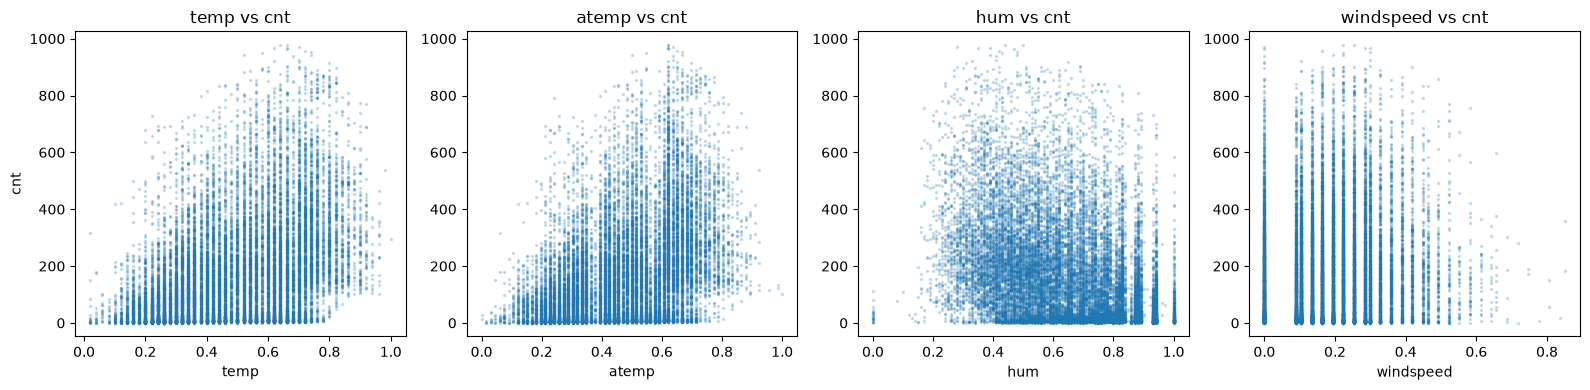

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, numericas):
    ax.scatter(bike[col], bike['cnt'], s=2, alpha=0.2)
    ax.set_title(f'{col} vs cnt')
    ax.set_xlabel(col)
axes[0].set_ylabel('cnt')
plt.tight_layout()
plt.show()

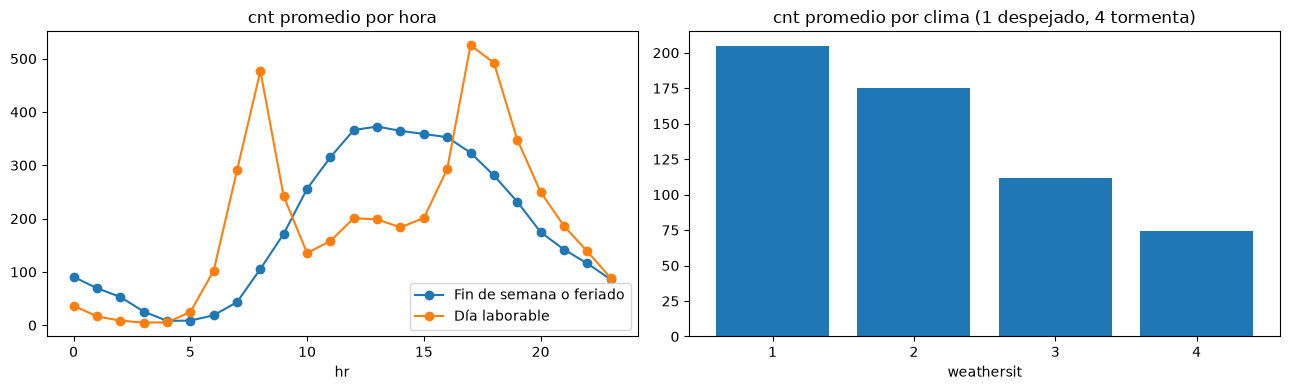

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

por_hora = bike.groupby(['hr', 'workingday'])['cnt'].mean().unstack()
axes[0].plot(por_hora[0], marker='o', label='Fin de semana o feriado')
axes[0].plot(por_hora[1], marker='o', label='Día laborable')
axes[0].set_title('cnt promedio por hora')
axes[0].set_xlabel('hr')
axes[0].legend()

por_clima = bike.groupby('weathersit')['cnt'].mean()
axes[1].bar(por_clima.index, por_clima.values)
axes[1].set_title('cnt promedio por clima (1 despejado, 4 tormenta)')
axes[1].set_xlabel('weathersit')
axes[1].set_xticks(por_clima.index)
plt.tight_layout()
plt.show()

- La temperatura es la numérica que más se relaciona con la demanda (r = 0.40): más calor, más alquileres. `temp` y `atemp` están casi duplicadas entre sí (r = 0.99).
- La humedad va en contra (r = -0.32) y el viento casi no influye (r = 0.09).
- La hora es lo que más pesa, pero no en línea recta: los días laborables tienen dos picos (8:00 y 17:00 a 18:00, ir y volver del trabajo) y los fines de semana una sola loma al mediodía. Por eso `hr` se trata como categórica y no como número.
- Con mal clima baja la demanda: de 205 alquileres por hora con cielo despejado a 112 con lluvia.
- `yr` tiene r = 0.25: en 2012 se alquiló más que en 2011.

## 3.2 Preparación y partición 80/20 en orden cronológico

Aplicamos la regla de la sección 1.3: dummies para las categóricas y escalado estándar para las numéricas. El escalador se ajusta solo con el entrenamiento, para que la prueba no influya en él.

Para la partición usamos `shuffle=False`: el 80% más antiguo entrena y el 20% más reciente prueba. Si mezcláramos las filas, el modelo entrenaría con horas del futuro que luego se le pide predecir. El archivo ya viene ordenado por fecha y hora.

In [6]:
X = bike.drop(columns=['dteday', 'cnt'])
X = pd.get_dummies(X, columns=categoricas, drop_first=True)
y = bike['cnt']

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X, y, test_size=0.2, shuffle=False)

scaler = StandardScaler()
X_train_reg[numericas] = scaler.fit_transform(X_train_reg[numericas])
X_test_reg[numericas] = scaler.transform(X_test_reg[numericas])

print('Columnas después de las dummies:', X.shape[1])
print('Entrenamiento:', bike['dteday'].iloc[0], 'a', bike['dteday'].iloc[len(X_train_reg) - 1])
print('Prueba:       ', bike['dteday'].iloc[len(X_train_reg)], 'a', bike['dteday'].iloc[-1])
print('cnt promedio en entrenamiento:', round(y_train_reg.mean(), 1))
print('cnt promedio en prueba:       ', round(y_test_reg.mean(), 1))

Columnas después de las dummies: 53
Entrenamiento: 2011-01-01 a 2012-08-07
Prueba:        2012-08-07 a 2012-12-31
cnt promedio en entrenamiento: 174.6
cnt promedio en prueba:        248.8


La prueba cubre agosto a diciembre de 2012, cuando el sistema ya había crecido: su demanda promedio es 42% mayor que la del entrenamiento. Eso hace la prueba más difícil, y es lo que pasaría en la vida real.

## 3.3 Regresión lineal múltiple y árbol de decisión para regresión

In [7]:
lineal = LinearRegression()
lineal.fit(X_train_reg, y_train_reg)

coeficientes = pd.Series(lineal.coef_, index=X.columns)
coeficientes.sort_values(ascending=False).head(5)

hr_17    348.291751
hr_18    322.067397
hr_8     283.618858
hr_19    223.163753
hr_16    203.775535
dtype: float64

Los coeficientes más grandes son las horas pico: a las 17:00 se alquilan unas 348 bicicletas más que a medianoche, con todo lo demás igual.

Para el árbol hay que escoger `max_depth`, porque sin límite memoriza el entrenamiento. Probamos varias profundidades con una validación: el último 20% del entrenamiento, también sin mezclar. Así no usamos la prueba para escoger.

In [8]:
X_sub, X_val, y_sub, y_val = train_test_split(X_train_reg, y_train_reg, test_size=0.2, shuffle=False)

for profundidad in [5, 10, 15, 20, None]:
    arbol = DecisionTreeRegressor(max_depth=profundidad, random_state=42)
    arbol.fit(X_sub, y_sub)
    rmse = mean_squared_error(y_val, arbol.predict(X_val)) ** 0.5
    print(f'max_depth={profundidad}: RMSE en validación = {rmse:.1f}')

max_depth=5: RMSE en validación = 170.7
max_depth=10: RMSE en validación = 155.8


max_depth=15: RMSE en validación = 130.0
max_depth=20: RMSE en validación = 137.9


max_depth=None: RMSE en validación = 130.5


In [9]:
arbol = DecisionTreeRegressor(max_depth=15, random_state=42)
arbol.fit(X_train_reg, y_train_reg)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",15
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with `

`max_depth=15` dio el menor error en validación, así que entrenamos el árbol final con esa profundidad y todo el entrenamiento.

## 3.4 MAE, RMSE y R²

- **MAE**: cuántas bicicletas se equivoca el modelo en promedio.
- **RMSE**: parecido, pero castiga más los errores grandes.
- **R²**: qué parte de la variación de `cnt` explica el modelo (1 es perfecto, 0 es igual que predecir siempre el promedio).

In [10]:
pred_lineal = lineal.predict(X_test_reg)
pred_arbol = arbol.predict(X_test_reg)

resultados = pd.DataFrame({
    'MAE': [mean_absolute_error(y_test_reg, pred_lineal), mean_absolute_error(y_test_reg, pred_arbol)],
    'RMSE': [mean_squared_error(y_test_reg, pred_lineal) ** 0.5, mean_squared_error(y_test_reg, pred_arbol) ** 0.5],
    'R² prueba': [r2_score(y_test_reg, pred_lineal), r2_score(y_test_reg, pred_arbol)],
    'R² entrenamiento': [lineal.score(X_train_reg, y_train_reg), arbol.score(X_train_reg, y_train_reg)],
}, index=['Regresión lineal', 'Árbol de decisión'])
resultados.round(3)

,MAE,RMSE,R² prueba,R² entrenamiento
Regresión lineal,98.798,133.835,0.632,0.689
Árbol de decisión,81.601,119.682,0.705,0.883


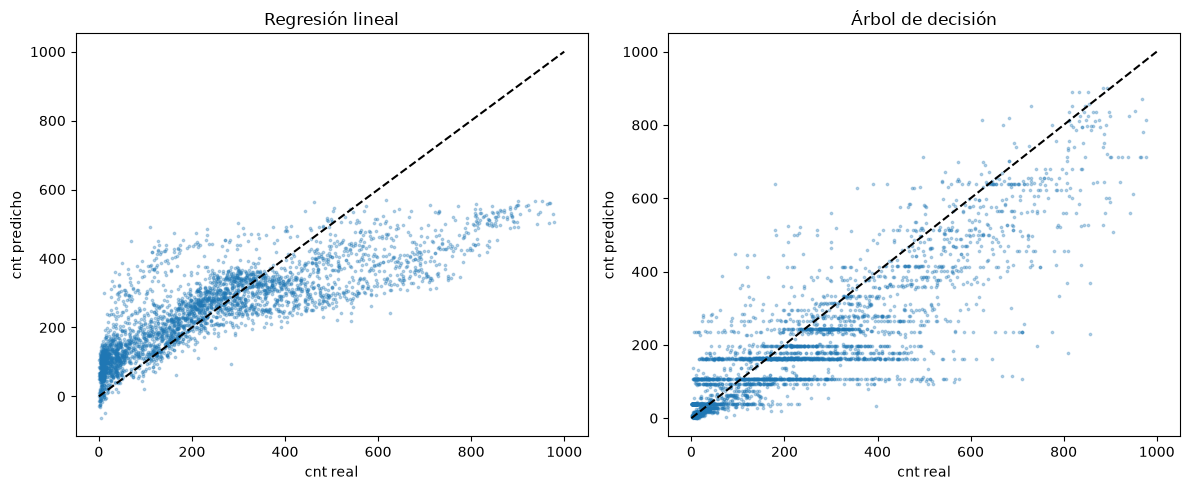

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, pred, nombre in zip(axes, [pred_lineal, pred_arbol], ['Regresión lineal', 'Árbol de decisión']):
    ax.scatter(y_test_reg, pred, s=3, alpha=0.3)
    ax.plot([0, 1000], [0, 1000], color='black', linestyle='--')
    ax.set_title(nombre)
    ax.set_xlabel('cnt real')
    ax.set_ylabel('cnt predicho')
plt.tight_layout()
plt.show()

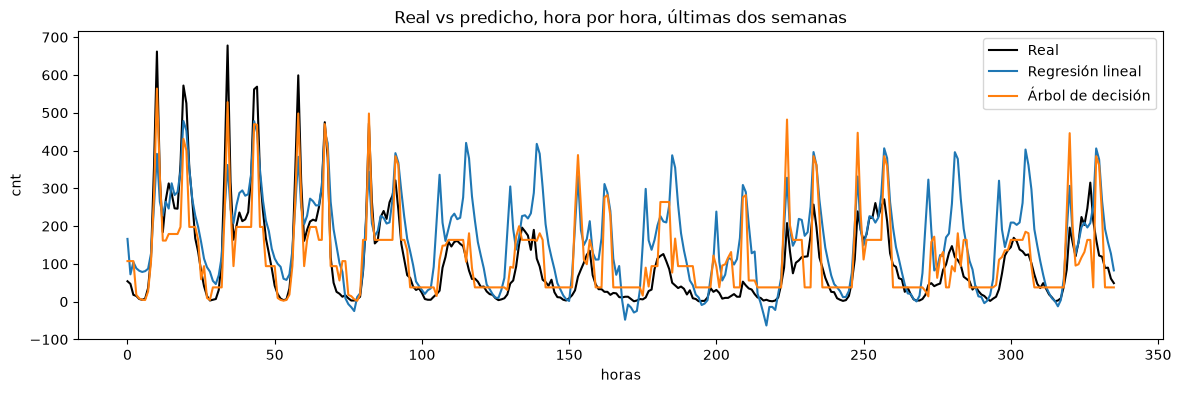

In [12]:
# Últimas dos semanas de la prueba (18 al 31 de diciembre de 2012)
plt.figure(figsize=(14, 4))
plt.plot(y_test_reg.values[-336:], color='black', label='Real')
plt.plot(pred_lineal[-336:], label='Regresión lineal')
plt.plot(pred_arbol[-336:], label='Árbol de decisión')
plt.title('Real vs predicho, hora por hora, últimas dos semanas')
plt.xlabel('horas')
plt.ylabel('cnt')
plt.legend()
plt.show()

El árbol gana en las tres métricas. En la dispersión, sus puntos están más cerca de la línea punteada (la predicción perfecta). En las dos últimas semanas, los dos modelos copian bien la forma del día, pero en Navidad predicen mucho más de lo que realmente se alquiló.

## 3.5 Análisis de errores y modelo elegido

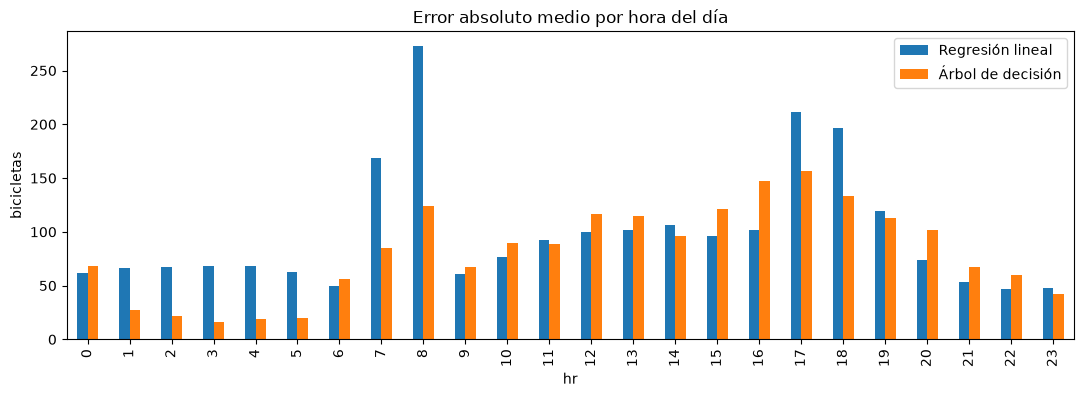

Predicciones negativas de la regresión lineal: 22
Error medio del árbol (predicho - real): -46.4


In [13]:
errores = pd.DataFrame({
    'hr': bike['hr'].iloc[len(X_train_reg):].values,
    'Regresión lineal': np.abs(pred_lineal - y_test_reg.values),
    'Árbol de decisión': np.abs(pred_arbol - y_test_reg.values),
})
errores.groupby('hr').mean().plot.bar(figsize=(13, 4), title='Error absoluto medio por hora del día')
plt.ylabel('bicicletas')
plt.show()

print('Predicciones negativas de la regresión lineal:', (pred_lineal < 0).sum())
print('Error medio del árbol (predicho - real):', round((pred_arbol - y_test_reg).mean(), 1))

- Los dos modelos fallan más en las horas pico. La regresión lineal se equivoca por unas 270 bicicletas a las 8:00, porque suma el mismo efecto de la hora un lunes que un sábado. El árbol sí distingue esa combinación.
- En la madrugada el árbol casi no falla, mientras que la regresión lineal predice de más y hasta da valores negativos, que no tienen sentido para un conteo.
- En promedio el árbol se queda corto: predice menos de lo que se alquiló. Es por el crecimiento: el árbol solo predice promedios de lo que vio en el entrenamiento, y la demanda de finales de 2012 fue más alta.
- El árbol tiene más sobreajuste (R² de 0.883 en entrenamiento y 0.705 en prueba), pero aun así le gana a la regresión lineal en datos que no vio.

**Modelo elegido: el árbol de decisión.** Tiene menor MAE y RMSE, mayor R², no da predicciones negativas y capta mejor la diferencia entre días laborables y fines de semana.

## 3.6 Pregunta de análisis: ¿es confiable para decisiones reales?

Para planificar, sí. El árbol explica el 70% de la variación de la demanda en meses que no vio, y acierta cuándo sube y cuándo baja. Eso sirve para decidir en qué horas reforzar la redistribución de bicicletas, cuándo hacer mantenimiento (de madrugada, donde casi no falla) o cuánto baja la demanda con lluvia.

Para decisiones exactas hora por hora, todavía no. Un MAE de 81.6 bicicletas sobre un promedio de 248.8 es un error de un 33%, y en las tardes de los laborables el error es mayor y casi siempre por debajo de lo real. Si una empresa planificara su flota de la tarde solo con este modelo, le faltarían bicicletas. Tampoco puede anticipar feriados como Navidad.

# 4. Interpretación desde Inteligencia de Negocios

## 4.1 Cómo usaría una organización estos modelos para decidir mejor

**El banco.** El modelo de clasificación le dice a quién llamar primero. En vez de llamar a toda la base, la campaña se enfoca en los clientes que el modelo marca como probables suscriptores, y ahorra llamadas a quienes casi seguro dirán que no. [COMPLETAR con la sección 2: modelo elegido y su recall o precisión para `yes`.]

**El sistema de bicicletas.** El modelo de regresión convierte el pronóstico del clima y el calendario en una estimación de cuántas bicicletas se van a pedir cada hora. Con eso se puede:

- mover bicicletas a las estaciones antes de los picos de las 8:00 y las 17:00 de los días laborables;
- hacer mantenimiento de madrugada, que es cuando menos se usa el sistema;
- ajustar personal o lanzar promociones los días de lluvia, cuando la demanda baja casi a la mitad;
- justificar la compra de más bicicletas, porque la demanda de 2012 fue claramente mayor que la de 2011.

## 4.2 Limitaciones y qué mejorar antes de usarlos en un entorno real

**Limitaciones**

- El modelo de regresión no capta bien el crecimiento: se queda corto en los meses más recientes.
- No sabe de eventos ni de feriados especiales (Navidad, huracanes), que son los días en que más falla.
- Los datos son de una sola ciudad, de 2011 y 2012, y del sistema completo, no por estación.
- La regresión lineal da predicciones negativas y no combina hora con tipo de día.
- En la clasificación: [COMPLETAR con la sección 2: desbalance de `y` y el error que más comete el modelo elegido].

**Qué mejorar**

- Agregar datos de eventos, feriados y la demanda de días anteriores.
- Reentrenar el modelo cada cierto tiempo para que siga el crecimiento.
- Probar modelos más fuertes, como random forest, que combinan muchos árboles.
- En la clasificación, ajustar el umbral según cuánto cuesta un falso positivo y un falso negativo.